In [1]:
from __future__ import annotations

import json
import os
from typing import Any, Literal, TypedDict

import pandas as pd
import requests
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, ConfigDict, Field

In [2]:
load_dotenv()

NASA_POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
NASA_PARAMETERS = ["T2M", "T2M_MAX", "T2M_MIN", "PRECTOTCORR"]
NASA_COMMUNITY = "AG"

START_DATE = os.getenv("NASA_START_DATE", "20250101")
END_DATE = os.getenv("NASA_END_DATE", "20251231")

GROQ_API_KEY = os.getenv("GROQ_API_KEY")
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")
GROQ_MODEL = os.getenv("GROQ_MODEL", "openai/gpt-oss-20b")

In [3]:
# Demo profile. Replace these values with the farmer's actual profile.
FARM_DATA = {
    "farmName": "Demo Farm",
    "location": "Damanhur, Beheira, Egypt",
    "latitude": 31.04,
    "longitude": 30.47,
    "cultivatedArea": 5.0,
    "areaUnit": "Acres",
    "soilType": "Sandy loam",
    "soilPH": 7.5,
    "soilSalinityEC": 1.2,
    "soilOrganicMatter": 1.8,
    "currentCrop": "Maize",
    "previousWinterCrop": "Wheat",
    "cropHistory": [
        {"crop": "Wheat", "season": "Winter", "year": 2024},
        {"crop": "Maize", "season": "Summer", "year": 2024},
        {"crop": "Wheat", "season": "Winter", "year": 2025},
        {"crop": "Maize", "season": "Summer", "year": 2025},
    ],
    "plantingDate": "2026-05-01",
    "expectedHarvestDate": "2026-09-15",
    "waterSource": "Nile irrigation canal",
    "irrigationMethod": "Surface irrigation",
    "irrigationFrequency": "Every 10 days",
    "availableWaterAmount": 3000,
    "availableWaterUnit": "m3 per acre per season",
    "farmerGoal": [
        "Improve soil health",
        "Maintain crop productivity",
        "Reduce water consumption",
    ],
    "goalPriority": [
        "Improve soil health",
        "Maintain crop productivity",
        "Reduce water consumption",
    ],
}

In [4]:
# ============================================================
# 2. STRUCTURED OUTPUT MODELS
# ============================================================

class StrictOutputModel(BaseModel):
    model_config = ConfigDict(extra="forbid")


class RotationStrategy(StrictOutputModel):
    name: str = Field(description="Short, distinct strategy name")
    crop_sequence: list[str] = Field(
        description="Ordered crops in the proposed rotation"
    )
    seasons: list[str] = Field(
        description="Season corresponding to each crop in crop_sequence"
    )
    rationale: str = Field(description="Concise explanation of the rotation")
    expected_benefits: list[str] = Field(
        description="Potential benefits, without unsupported numerical claims"
    )
    risks_and_uncertainties: list[str] = Field(
        description="Risks, assumptions, and points needing local verification"
    )
    evidence_used: list[str] = Field(
        description="Titles of supplied evidence sources supporting the strategy"
    )


class StrategyOutput(StrictOutputModel):
    strategies: list[RotationStrategy] = Field(
        description=(
            "REQUIRED: exactly three complete and meaningfully different "
            "crop-rotation strategy objects. Never omit this field, even when "
            "some agronomic details are uncertain."
        )
    )
    overall_notes: list[str] = Field(
        description="Important cross-strategy notes and missing information"
    )

In [5]:
# ============================================================
# 3. SHARED STATE
# ============================================================

class FieldShiftState(TypedDict, total=False):
    farm: dict[str, Any]
    climate_data: list[dict[str, Any]]
    climate_summary: dict[str, Any]
    research_results: list[dict[str, Any]]
    strategy_output: dict[str, Any]
    validation: dict[str, Any]
    error: str

In [6]:
# ============================================================
# 4. HELPERS
# ============================================================

def require_api_keys() -> None:
    missing = []
    if not GROQ_API_KEY:
        missing.append("GROQ_API_KEY")
    if not TAVILY_API_KEY:
        missing.append("TAVILY_API_KEY")
    if missing:
        raise RuntimeError(
            "Missing API key(s): "
            + ", ".join(missing)
            + ". Add them to the .env file."
        )


def get_llm() -> ChatGroq:
    return ChatGroq(
        model=GROQ_MODEL,
        temperature=0.2,
        api_key=GROQ_API_KEY,
    )


def content_to_text(response: Any) -> str:
    """Extract readable text from a LangChain AIMessage or plain string."""
    content = getattr(response, "content", response)

    if isinstance(content, str):
        return content

    if isinstance(content, list):
        parts = []
        for item in content:
            if isinstance(item, dict) and item.get("type") == "text":
                parts.append(item.get("text", ""))
            elif isinstance(item, str):
                parts.append(item)
        return "\n".join(parts)

    return str(content)


def save_json_file(data: Any, file_path: str) -> None:
    """Save a JSON result or debugging record immediately."""
    with open(file_path, "w", encoding="utf-8") as file:
        json.dump(
            data,
            file,
            ensure_ascii=False,
            indent=2,
            default=str,
        )


def invoke_structured_once(
    llm: ChatGroq,
    schema: type[BaseModel],
    system_prompt: str,
    user_prompt: str,
    output_path: str,
) -> BaseModel:
    """
    Make exactly one model call using tool/function structured output; Pydantic validates the result.
    Save the validated result, or save raw debugging details if it fails.
    """

    structured_llm = llm.with_structured_output(
        schema,
        method="function_calling",
        strict=False,
        include_raw=True,
    )

    try:
        response = structured_llm.invoke([
            SystemMessage(content=system_prompt),
            HumanMessage(content=user_prompt),
        ])
    except Exception as exc:
        debug_path = output_path.replace(".json", "_debug.json")
        save_json_file(
            {
                "status": "model_call_failed",
                "error_type": type(exc).__name__,
                "error": str(exc),
            },
            debug_path,
        )
        raise

    raw_message = response.get("raw")
    parsed_result = response.get("parsed")
    parsing_error = response.get("parsing_error")

    raw_text = content_to_text(raw_message) if raw_message else ""
    metadata = getattr(raw_message, "response_metadata", {}) if raw_message else {}

    if parsing_error is not None or parsed_result is None:
        debug_path = output_path.replace(".json", "_debug.json")

        save_json_file(
            {
                "status": "structured_output_failed",
                "raw_response": raw_text,
                "response_metadata": metadata,
                "parsing_error": str(parsing_error),
            },
            debug_path,
        )

        print("\nSTRUCTURED OUTPUT FAILED")
        print("Raw response:")
        print(repr(raw_text))
        print("Parsing error:", parsing_error)
        print("Debug details saved to:", debug_path)

        raise ValueError(
            f"Could not produce valid {schema.__name__} output. "
            f"See {debug_path} for the raw response and error."
        )

    # Pydantic object has already been validated by with_structured_output.
    result_data = (
        parsed_result.model_dump()
        if isinstance(parsed_result, BaseModel)
        else parsed_result
    )

    save_json_file(result_data, output_path)
    print(f"Structured output saved to: {output_path}")

    return parsed_result

In [7]:
# ============================================================
# 5. NODE 1 - GET NASA POWER HISTORICAL DATA
# ============================================================

def get_nasa_data(
    latitude: float,
    longitude: float,
    start_date: str,
    end_date: str,
) -> pd.DataFrame:
    params = {
        "parameters": ",".join(NASA_PARAMETERS),
        "community": NASA_COMMUNITY,
        "longitude": longitude,
        "latitude": latitude,
        "start": start_date,
        "end": end_date,
        "format": "JSON",
        "time-standard": "UTC",
    }

    response = requests.get(NASA_POWER_URL, params=params, timeout=90)
    response.raise_for_status()
    payload = response.json()

    try:
        parameter_data = payload["properties"]["parameter"]
    except KeyError as exc:
        raise ValueError(
            "Unexpected NASA POWER response: 'properties.parameter' was not found."
        ) from exc

    df = pd.DataFrame(parameter_data)
    df.index = pd.to_datetime(df.index, format="%Y%m%d", errors="coerce")
    df.index.name = "date"
    df = df.reset_index()

    for column in NASA_PARAMETERS:
        if column not in df.columns:
            raise ValueError(f"NASA POWER response is missing {column}.")

    df[NASA_PARAMETERS] = df[NASA_PARAMETERS].apply(
        pd.to_numeric, errors="coerce"
    )
    df[NASA_PARAMETERS] = df[NASA_PARAMETERS].replace(-999, float("nan"))
    df = df.dropna(subset=["date"])

    if df[NASA_PARAMETERS].notna().sum().sum() == 0:
        raise ValueError(
            "NASA POWER returned no valid values for the requested parameters "
            "and dates. Check the response and date range before continuing."
        )

    return df


def nasa_collection_node(state: FieldShiftState) -> dict[str, Any]:
    farm = state["farm"]
    print("\n[1/6] Downloading historical climate data from NASA POWER...")

    df = get_nasa_data(
        latitude=float(farm["latitude"]),
        longitude=float(farm["longitude"]),
        start_date=START_DATE,
        end_date=END_DATE,
    )

    records = df.assign(
        date=df["date"].dt.strftime("%Y-%m-%d")
    ).to_dict(orient="records")

    print(f"Downloaded {len(records)} daily records.")
    return {"climate_data": records}

In [8]:

# ============================================================
# 6. NODE 2 - ANALYZE CLIMATE DATA
# ============================================================

def analyze_climate_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[2/6] Analyzing climate data...")

    df = pd.DataFrame(state["climate_data"])
    df["date"] = pd.to_datetime(df["date"])

    summary: dict[str, Any] = {
        "period": f"{START_DATE} to {END_DATE}",
        "valid_daily_records": int(len(df)),
        "missing_values": {},
        "annual": {},
        "monthly": [],
    }

    for column in NASA_PARAMETERS:
        summary["missing_values"][column] = int(df[column].isna().sum())

    if "T2M" in df:
        summary["annual"]["average_temperature_c"] = round(
            float(df["T2M"].mean()), 2
        ) if df["T2M"].notna().any() else None

    if "T2M_MAX" in df:
        summary["annual"]["highest_daily_max_temperature_c"] = round(
            float(df["T2M_MAX"].max()), 2
        ) if df["T2M_MAX"].notna().any() else None

    if "T2M_MIN" in df:
        summary["annual"]["lowest_daily_min_temperature_c"] = round(
            float(df["T2M_MIN"].min()), 2
        ) if df["T2M_MIN"].notna().any() else None

    if "PRECTOTCORR" in df:
        summary["annual"]["total_precipitation_mm"] = round(
            float(df["PRECTOTCORR"].sum()), 2
        ) if df["PRECTOTCORR"].notna().any() else None

    df["month"] = df["date"].dt.month
    monthly = df.groupby("month").agg(
        mean_temperature_c=("T2M", "mean"),
        precipitation_mm=("PRECTOTCORR", "sum"),
        mean_daily_max_temperature_c=("T2M_MAX", "mean"),
        mean_daily_min_temperature_c=("T2M_MIN", "mean"),
    ).reset_index()

    summary["monthly"] = monthly.round(2).where(
        pd.notna(monthly), None
    ).to_dict(orient="records")

    print(json.dumps(summary["annual"], indent=2))
    return {"climate_summary": summary}


In [9]:
# ============================================================
# 7. NODE 3 - AGRICULTURAL RESEARCH WITH TAVILY
# ============================================================

def research_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[3/6] Searching for agricultural research with Tavily...")

    farm = state["farm"]
    climate = state["climate_summary"]

    query = (
        f"Scientific studies and agricultural extension research about crop "
        f"rotation suitable for {farm['location']}, Egypt, under conditions "
        f"similar to {farm['soilType']} soil. Consider crop rotation after "
        f"{farm['currentCrop']}, soil organic matter, salinity, irrigation "
        f"water limitations, heat and rainfall patterns. Prioritize Egypt, "
        f"Nile Delta, and Mediterranean climate studies. Find evidence about "
        f"seasonal suitability, soil health, legumes, crop water requirements, "
        f"and rotation constraints. Climate summary: "
        f"{json.dumps(climate['annual'], ensure_ascii=False)}"
    )

    search_tool = TavilySearch(
        max_results=6,
        search_depth="basic",
        topic="general",
        include_answer=False,
        include_raw_content=False,
    )

    result = search_tool.invoke({"query": query})

    if isinstance(result, dict):
        results = result.get("results", [])
    elif isinstance(result, list):
        results = result
    else:
        results = []

    cleaned = []
    for item in results:
        if not isinstance(item, dict):
            continue

        cleaned.append({
            "title": item.get("title", "Untitled"),
            "url": item.get("url", ""),
            "content": (item.get("content") or "")[:1800],
            "score": item.get("score"),
        })

    if not cleaned:
        raise ValueError(
            "Tavily returned no search results. Check TAVILY_API_KEY "
            "and the search query."
        )

    print(f"Found {len(cleaned)} research sources.")
    print("Raw source excerpts will be passed directly to the strategy-generation model.")

    # Keep source text and provenance for the strategy-generation model.
    return {"research_results": cleaned}

In [ ]:
# ============================================================
# 8. EVIDENCE EVALUATION - SKIPPED
# ============================================================
# To reduce API calls and avoid a second model-output failure,
# Tavily source excerpts are passed directly to strategy_generation_node.
# The strategy-generation model must assess the supplied sources itself.


In [10]:
# ============================================================
# 9. NODE 4 - GENERATE THREE CROP ROTATION STRATEGIES
# ============================================================

STRATEGY_SYSTEM_PROMPT = """
You are an agricultural decision-support model for Field Shift.

MANDATORY OUTPUT:
- You MUST return the "strategies" field containing exactly THREE complete strategy objects.
- You MUST also return the "overall_notes" field.
- Never return overall_notes alone. Never omit strategies.
- If evidence is incomplete, still provide three provisional candidate rotations.
  Put uncertain crop suitability and assumptions in risks_and_uncertainties.
  Do not replace the strategies with a list of limitations.

Use the supplied farm profile, NASA POWER historical climate analysis,
and the raw Tavily research excerpts. Assess source relevance yourself.

For every strategy:
- Provide a distinct crop sequence and its corresponding seasons.
- Respect the known crop history, soil, irrigation, and farmer goals.
- Use only supplied research source titles in evidence_used.
- Explain the reasoning and distinguish evidence from assumptions.
- State risks and what needs local agronomist verification.

Across all strategies:
- Do not invent yields, profits, water savings, or numerical improvements.
- NASA POWER data here describe historical temperature and precipitation;
  they do not directly measure soil health or crop water use.
- Do not invent exact planting dates.
- Do not claim a crop is locally suitable unless the supplied evidence supports it.
"""


def strategy_generation_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[4/5] Generating crop-rotation strategies...")

    llm = get_llm()

    user_prompt = f"""
Farm profile:
{json.dumps(state["farm"], ensure_ascii=False)}

NASA POWER historical climate analysis:
{json.dumps(state["climate_summary"], ensure_ascii=False)}

Tavily agricultural research sources (original titles, URLs, and excerpts):
{json.dumps(state["research_results"], ensure_ascii=False)}

Return all required fields. The "strategies" array is mandatory and must
contain exactly 3 complete objects, even if some recommendations are provisional.
Review the supplied Tavily excerpts directly. Use only source titles that
actually appear in research_results in evidence_used. Do not invent citations.
Put missing information and assumptions in risks_and_uncertainties and overall_notes;
do not omit the strategies array.

For each strategy provide:
- name
- crop_sequence
- seasons (one season for each crop)
- rationale
- expected_benefits
- risks_and_uncertainties
- evidence_used (source titles only)

Also provide overall_notes for major assumptions, evidence limitations,
and information that should be checked locally.
"""

    strategy_result = invoke_structured_once(
        llm=llm,
        schema=StrategyOutput,
        system_prompt=STRATEGY_SYSTEM_PROMPT,
        user_prompt=user_prompt,
        output_path="strategy_output.json",
    )

    if len(strategy_result.strategies) != 3:
        raise ValueError(
            f"The model returned {len(strategy_result.strategies)} strategies; "
            "exactly 3 are required. The model output was saved for inspection."
        )

    result = strategy_result.model_dump()
    print("Generated exactly 3 strategies.")

    return {"strategy_output": result}

In [11]:

# ============================================================
# 10. NODE 5 - BASIC PROGRAMMATIC VALIDATION
# ============================================================

def strategy_validation_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[5/5] Validating the generated strategies...")

    strategies = state["strategy_output"]["strategies"]
    farm = state["farm"]
    warnings: list[str] = []
    checks: list[dict[str, Any]] = []

    for index, strategy in enumerate(strategies, start=1):
        crops = strategy.get("crop_sequence", [])
        seasons = strategy.get("seasons", [])

        valid_sequence = isinstance(crops, list) and len(crops) >= 2
        matching_seasons = len(crops) == len(seasons)

        if not valid_sequence:
            warnings.append(
                f"Strategy {index}: crop sequence should contain at least 2 crops."
            )
        if not matching_seasons:
            warnings.append(
                f"Strategy {index}: number of seasons does not match number of crops."
            )

        normalized = [str(c).strip().casefold() for c in crops]
        if len(normalized) != len(set(normalized)):
            warnings.append(
                f"Strategy {index}: a crop is repeated in the proposed sequence. "
                "This is a review flag, not an automatic agronomic rejection."
            )

        current_crop = str(farm.get("currentCrop", "")).strip().casefold()
        if normalized and normalized[0] == current_crop:
            warnings.append(
                f"Strategy {index}: first proposed crop is the same as the "
                "current crop; verify the intended rotation timing."
            )

        checks.append({
            "strategy": strategy.get("name", f"Strategy {index}"),
            "has_at_least_two_crops": valid_sequence,
            "crop_and_season_counts_match": matching_seasons,
        })

    validation = {
        "passed_basic_structure_check": all(
            item["has_at_least_two_crops"]
            and item["crop_and_season_counts_match"]
            for item in checks
        ),
        "checks": checks,
        "warnings": warnings,
        "important_note": (
            "These are structural checks only. They do not prove agronomic "
            "suitability. A local agronomist should verify crop calendars, "
            "soil constraints, and irrigation requirements."
        ),
    }

    return {"validation": validation}

In [12]:

# ============================================================
# 11. BUILD LANGGRAPH
# ============================================================
from IPython.display import Image, display
def build_graph():
    builder = StateGraph(FieldShiftState)

    builder.add_node("nasa_collection", nasa_collection_node)
    builder.add_node("climate_analysis", analyze_climate_node)
    builder.add_node("agricultural_research", research_node)
    builder.add_node("strategy_generation", strategy_generation_node)
    builder.add_node("strategy_validation", strategy_validation_node)

    builder.add_edge(START, "nasa_collection")
    builder.add_edge("nasa_collection", "climate_analysis")
    builder.add_edge("climate_analysis", "agricultural_research")
    builder.add_edge("agricultural_research", "strategy_generation")
    builder.add_edge("strategy_generation", "strategy_validation")
    builder.add_edge("strategy_validation", END)
    graph  = builder.compile()
    
    return graph



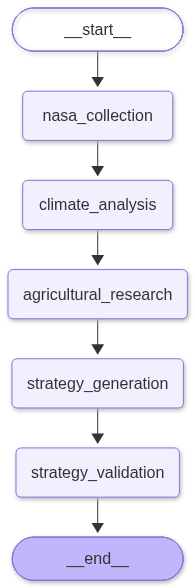

In [13]:
graph = build_graph()
display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
import json
import traceback

require_api_keys()

print("=" * 65)
print("FIELD SHIFT - ADAPTING FARMS WITH NASA DATA")
print("=" * 65)

print(f"Farm: {FARM_DATA['farmName']}")
print(f"Location: {FARM_DATA['location']}")
print(f"NASA period: {START_DATE} - {END_DATE}")
print(f"Groq model: {GROQ_MODEL}")

graph = build_graph()

initial_state: FieldShiftState = {
    "farm": FARM_DATA,
}

final_state = {}
workflow_completed = False
output_path = "field_shift_output.json"


def build_saved_output(state: dict[str, Any]) -> dict[str, Any]:
    return {
        "farm": FARM_DATA,
        "climate_summary": state.get("climate_summary"),
        "research_results": state.get("research_results"),
        "strategy_output": state.get("strategy_output"),
        "validation": state.get("validation"),
    }


try:
    print("\nStarting workflow...\n")

    for event in graph.stream(initial_state, stream_mode="updates"):
        for node_name, node_output in event.items():

            # Keep the full state in memory for the next LangGraph node.
            final_state.update(node_output)

            print("\n" + "=" * 65)
            print(f"NODE COMPLETED: {node_name}")
            print("=" * 65)

            # Avoid printing all 365 daily NASA records in the notebook.
            display_output = node_output
            if node_name == "nasa_collection":
                records = node_output.get("climate_data", [])
                display_output = {
                    "climate_data_records": len(records),
                    "first_record": records[0] if records else None,
                    "last_record": records[-1] if records else None,
                }

            print(json.dumps(
                display_output,
                ensure_ascii=False,
                indent=2,
                default=str,
            ))

            # Save the latest completed stage immediately.
            save_json_file(build_saved_output(final_state), output_path)
            print(f"Partial results saved to: {output_path}")

    workflow_completed = True

except Exception as exc:
    print("\n" + "!" * 65)
    print("WORKFLOW FAILED")
    print("!" * 65)

    print(f"Error type: {type(exc).__name__}")
    print(f"Error message: {exc}")

    print("\nFull traceback:")
    traceback.print_exc()

    print("\nLast successfully completed node outputs:")
    print(json.dumps(
        build_saved_output(final_state),
        ensure_ascii=False,
        indent=2,
        default=str,
    ))

finally:
    # Save whatever completed successfully, even if a later node failed.
    save_json_file(build_saved_output(final_state), output_path)
    print(f"\nResults saved to: {output_path}")


if workflow_completed:
    print("\n" + "=" * 65)
    print("PROJECT COMPLETED")
    print("=" * 65)

    strategies = (
        (final_state.get("strategy_output") or {}).get("strategies", [])
    )

    for number, strategy in enumerate(strategies, start=1):
        print(f"\n{number}. {strategy['name']}")
        print("Crops:", " -> ".join(strategy["crop_sequence"]))
        print("Seasons:", " -> ".join(strategy["seasons"]))
        print("Rationale:", strategy["rationale"])

    print("\nValidation:")
    print(json.dumps(
        final_state.get("validation"),
        ensure_ascii=False,
        indent=2,
        default=str,
    ))
else:
    print("\nWORKFLOW FAILED - PARTIAL RESULTS SAVED")
    print("Check the error above and the *_debug.json file if a model call failed.")

FIELD SHIFT - ADAPTING FARMS WITH NASA DATA
Farm: Demo Farm
Location: Damanhur, Beheira, Egypt
NASA period: 20250101 - 20251231
Groq model: openai/gpt-oss-20b

Starting workflow...


[1/6] Downloading historical climate data from NASA POWER...
Downloaded 365 daily records.

NODE COMPLETED: nasa_collection
{
  "climate_data_records": 365,
  "first_record": {
    "date": "2025-01-01",
    "T2M": 14.8,
    "T2M_MAX": 20.73,
    "T2M_MIN": 10.46,
    "PRECTOTCORR": 0.02
  },
  "last_record": {
    "date": "2025-12-31",
    "T2M": 14.12,
    "T2M_MAX": 20.44,
    "T2M_MIN": 8.65,
    "PRECTOTCORR": 0.02
  }
}
Partial results saved to: field_shift_output.json

[2/6] Analyzing climate data...
{
  "average_temperature_c": 22.73,
  "highest_daily_max_temperature_c": 43.64,
  "lowest_daily_min_temperature_c": 5.63,
  "total_precipitation_mm": 62.51
}

NODE COMPLETED: climate_analysis
{
  "climate_summary": {
    "period": "20250101 to 20251231",
    "valid_daily_records": 365,
    "missing_value

In [ ]:
llm = get_llm()

response = llm.invoke(
    'Return only this JSON object: {"status": "ok"}'
)

print("CONTENT:")
print(repr(response.content))

print("\nRESPONSE METADATA:")
print(response.response_metadata)

In [ ]:
print(repr(response.content))